# Fundamentals of Data Science – Lab Solutions (Q5 – Q10)

### Dataset → question mapping
| Question | Topic | File used | Notes |
|---|---|---|---|
| Q5 | Fuel efficiency (NumPy) | *built-in sample* | no dataset was provided – swap in your own file via the config cell |
| Q6 | Cashier bill | `Sales_1.xlsx` | `Price`, `Quantity_Sold` columns |
| Q7 | Customer orders | `Exp7.csv` | `customer_name`, `order_date`, `product_name`, `quantity` |
| Q8 | Top-5 products | `Exp8.csv` | `product_name`, `quantity`, `order_date` |
| Q9 | Property analysis | `Exp9.csv` | housing data (no location / ID column – see note in Q9) |
| Q10 | Monthly sales plots | `Exp10.csv` | `order_date`, `sales` (aggregated month-wise) |


In [1]:
# Common imports, helper functions and plot theme (run this cell first)
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 25)
pd.options.display.float_format = "{:,.2f}".format

# ---- consistent colour palette + clean chart style -------------------------
BLUE, ORANGE, GREEN, GREY, NAVY = "#3B7DD8", "#F28E2B", "#59A14F", "#8A94A6", "#1F3A5F"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#E6E9EF", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 10.5, "axes.labelcolor": "#333333", "xtick.color": "#444444", "ytick.color": "#444444",
    "font.size": 10, "legend.frameon": False,
})

# ---- helpers ---------------------------------------------------------------
def load_data(path):
    """Read a CSV / Excel file (with a friendly error if the file is not found)."""
    p = Path(path)
    if not p.exists():
        raise FileNotFoundError(f"'{path}' not found. Put it next to this notebook or give the full path.\n"
                                f"Current folder: {Path.cwd()}")
    return pd.read_excel(p) if p.suffix.lower() in (".xlsx", ".xls") else pd.read_csv(p)

def check_cols(df, cols):
    """Stop with a clear message if a configured column name is not in the DataFrame."""
    missing = [c for c in cols if c not in df.columns]
    if missing:
        raise KeyError(f"Column(s) {missing} not found.\nAvailable columns: {list(df.columns)}")

def clean_numeric(s):
    """Turn text such as '1,648' into the number 1648 (leaves real numbers untouched)."""
    if pd.api.types.is_numeric_dtype(s):
        return s
    return pd.to_numeric(s.astype(str).str.replace(",", "", regex=False).str.strip(), errors="coerce")

def parse_dates(s):
    """Parse dates written in mixed formats (13-01-2011, 1/1/2011, 2023-02-01 ...) -> day-first."""
    if pd.api.types.is_datetime64_any_dtype(s):
        return s
    s = s.astype(str).str.strip()
    out = pd.to_datetime(s, format="%d/%m/%Y", errors="coerce")
    for fmt in ("%d-%m-%Y", "%Y-%m-%d", "%m/%d/%Y"):
        out = out.fillna(pd.to_datetime(s, format=fmt, errors="coerce"))
    return out

def human(x, pos=None):
    """12_500 -> 12.5K, 2_300_000 -> 2.3M (for chart labels)."""
    if abs(x) >= 1e6: return f"{x/1e6:.1f}M".replace(".0M", "M")
    if abs(x) >= 1e3: return f"{x/1e3:.1f}K".replace(".0K", "K")
    return f"{x:,.0f}"

def show(df, n=None, **fmt):
    """Display a DataFrame nicely; fmt e.g. price="{:,.0f}" formats a column."""
    out = (df.head(n) if n else df).copy()
    for col, f in fmt.items():
        out[col] = out[col].map(f.format)
    display(out)

---
## Question 6 – Total cost of a purchase with discount and tax

**Formulae**
- `subtotal = Σ (price × quantity)`
- `discount = subtotal × discount% / 100`
- `tax = (subtotal − discount) × tax% / 100`  (tax is charged on the discounted amount)
- `total = subtotal − discount + tax`

The customer's basket is taken from **`Sales_1.xlsx`** (`Price` = item price, `Quantity_Sold` = quantity).
Set `USE_FILE = False` to type the prices / quantities by hand instead.

,Item,Price,Qty,Line total
0,#1 · ID 1015,371.40,30,"11,142.00"
1,#2 · ID 1021,"1,106.51",32,"35,408.32"
2,#3 · ID 1100,"1,137.44",43,"48,909.92"
3,#4 · ID 1024,641.09,21,"13,462.89"
4,#5 · ID 1022,"2,869.60",21,"60,261.60"
5,#6 · ID 1091,"2,406.58",44,"105,889.52"


Subtotal               :   275,074.25
Discount (10%)          :   -27,507.42
Amount after discount  :   247,566.83
Tax (5%)               :    12,378.34
--------------------------------------
TOTAL TO PAY           :   259,945.17


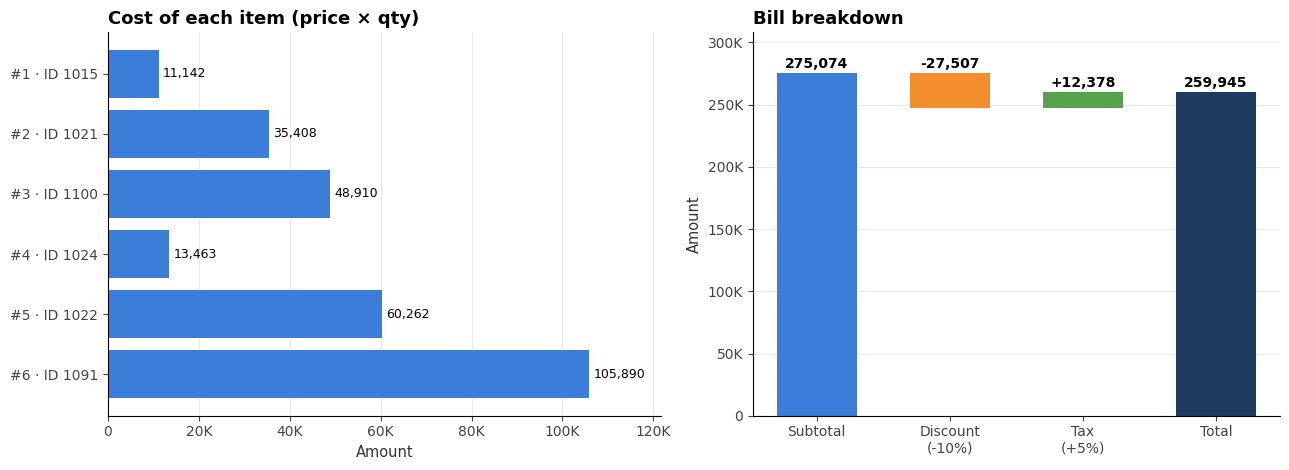

In [3]:
# ⚙️ CONFIG ---------------------------------------------------------------
USE_FILE   = True                # True -> take the basket from the file ; False -> use the manual lists below
DATA_FILE  = "/content/Sales (1).xlsx"
ITEM_COL   = "Product_ID"        # label for each item
PRICE_COL  = "Price"             # price per unit
QTY_COL    = "Quantity_Sold"     # units bought
FILTER_COL, FILTER_VALUE = "Product_Name", "Food"   # only items of this type (set FILTER_COL = None for all rows)
N_ITEMS    = 6                   # how many items are in the customer's basket (first N rows)

DISCOUNT_RATE = 10               # discount in %
TAX_RATE      = 5                # tax in %

# manual basket (used only when USE_FILE = False)
manual_items  = ["Rice", "Milk", "Bread", "Eggs", "Oil"]
manual_prices = [320.0, 56.0, 40.0, 84.0, 180.0]
manual_qty    = [1, 3, 2, 2, 1]
# --------------------------------------------------------------------------

if USE_FILE:
    d = load_data(DATA_FILE)
    check_cols(d, [ITEM_COL, PRICE_COL, QTY_COL] + ([FILTER_COL] if FILTER_COL else []))
    if FILTER_COL:
        d = d[d[FILTER_COL] == FILTER_VALUE]
    basket = d.head(N_ITEMS)
    item_names = [f"#{i+1} · ID {x}" for i, x in enumerate(basket[ITEM_COL])]
    prices, quantities = basket[PRICE_COL].tolist(), basket[QTY_COL].tolist()
else:
    item_names, prices, quantities = manual_items, manual_prices, manual_qty

def total_cost(prices, quantities, discount_rate, tax_rate):
    prices, quantities = np.array(prices, dtype=float), np.array(quantities, dtype=float)
    line_totals = prices * quantities                  # price x quantity for every item
    subtotal    = line_totals.sum()
    discount    = subtotal * discount_rate / 100
    after_disc  = subtotal - discount
    tax         = after_disc * tax_rate / 100
    return line_totals, subtotal, discount, after_disc, tax, after_disc + tax

line_totals, subtotal, discount, after_disc, tax, total = total_cost(prices, quantities, DISCOUNT_RATE, TAX_RATE)

bill = pd.DataFrame({"Item": item_names, "Price": prices, "Qty": quantities, "Line total": line_totals})
show(bill, Price="{:,.2f}", **{"Line total": "{:,.2f}"})

print(f"Subtotal               : {subtotal:>12,.2f}")
print(f"Discount ({DISCOUNT_RATE}%)          : {-discount:>12,.2f}")
print(f"Amount after discount  : {after_disc:>12,.2f}")
print(f"Tax ({TAX_RATE}%)               : {tax:>12,.2f}")
print("-" * 38)
print(f"TOTAL TO PAY           : {total:>12,.2f}")

# ---- visual: line totals + bill waterfall ----
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.05, 1]})
ax = axes[0]
bars = ax.barh(item_names[::-1], line_totals[::-1], color=BLUE)
ax.bar_label(bars, labels=[f"{v:,.0f}" for v in line_totals[::-1]], padding=3, fontsize=9)
ax.set_title("Cost of each item (price × qty)"); ax.set_xlabel("Amount"); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(FuncFormatter(human)); ax.set_xlim(0, line_totals.max() * 1.15)

ax = axes[1]
steps   = ["Subtotal", f"Discount\n(-{DISCOUNT_RATE}%)", f"Tax\n(+{TAX_RATE}%)", "Total"]
heights = [subtotal, discount, tax, total]
bottoms = [0, after_disc, after_disc, 0]
bars = ax.bar(steps, heights, bottom=bottoms, color=[BLUE, ORANGE, GREEN, NAVY], width=0.6)
for b, h, bt, txt in zip(bars, heights, bottoms, [f"{subtotal:,.0f}", f"-{discount:,.0f}", f"+{tax:,.0f}", f"{total:,.0f}"]):
    ax.text(b.get_x() + b.get_width() / 2, bt + h + subtotal * 0.015, txt, ha="center", fontsize=10, fontweight="bold")
ax.set_title("Bill breakdown"); ax.set_ylabel("Amount"); ax.grid(axis="x", visible=False)
ax.yaxis.set_major_formatter(FuncFormatter(human)); ax.set_ylim(0, subtotal * 1.12)
plt.tight_layout(); plt.show()

---
## Question 7 – Customer order analysis (Pandas)  –  `Exp7.csv`

1. Total number of orders per customer → `groupby(customer)` + count of unique `order_id`
2. Average order quantity per product → `groupby(product)[quantity].mean()`
3. Earliest and latest order date → `min()` / `max()`

> **Data cleaning:** the `order_date` column has mixed formats (`13-01-2011` and `1/1/2011`), so it is converted with the `parse_dates()` helper (day-first).
> One order can contain several products, so the number of orders is counted with **unique `order_id`s** (set `ORDER_ID_COL = None` to count rows instead).

In [4]:
# ⚙️ CONFIG ---------------------------------------------------------------
DATA_FILE    = "/content/Exp7.csv"
CUSTOMER_COL = "customer_name"
DATE_COL     = "order_date"
PRODUCT_COL  = "product_name"
QTY_COL      = "quantity"
ORDER_ID_COL = "order_id"        # set to None to count rows instead of unique orders
TOP_SHOW     = 10                # how many rows to display / plot
# --------------------------------------------------------------------------

order_data = load_data(DATA_FILE)
check_cols(order_data, [CUSTOMER_COL, DATE_COL, PRODUCT_COL, QTY_COL] + ([ORDER_ID_COL] if ORDER_ID_COL else []))
order_data[DATE_COL] = parse_dates(order_data[DATE_COL])

print(f"Rows: {len(order_data):,}   Customers: {order_data[CUSTOMER_COL].nunique():,}   "
      f"Products: {order_data[PRODUCT_COL].nunique():,}   Unparsed dates: {order_data[DATE_COL].isna().sum()}")
show(order_data[[c for c in [ORDER_ID_COL, CUSTOMER_COL, DATE_COL, PRODUCT_COL, QTY_COL] if c]], n=5)

Rows: 51,290   Customers: 795   Products: 3,788   Unparsed dates: 0


,order_id,customer_name,order_date,product_name,quantity
0,AG-2011-2040,Toby Braunhardt,2011-01-01,"Tenex Lockers, Blue",2
1,IN-2011-47883,Joseph Holt,2011-01-01,"Acme Trimmer, High Speed",3
2,HU-2011-1220,Annie Thurman,2011-01-01,"Tenex Box, Single Width",4
3,IT-2011-3647632,Eugene Moren,2011-01-01,"Enermax Note Cards, Premium",3
4,IN-2011-47883,Joseph Holt,2011-01-01,"Eldon Light Bulb, Duo Pack",5


In [5]:
# 1) Total number of orders made by each customer
if ORDER_ID_COL:
    orders_per_customer = order_data.groupby(CUSTOMER_COL)[ORDER_ID_COL].nunique()
else:
    orders_per_customer = order_data.groupby(CUSTOMER_COL).size()
orders_per_customer = orders_per_customer.sort_index().sort_values(ascending=False, kind="mergesort")
orders_per_customer.name = "total_orders"

print(f"1) Total orders per customer (top {TOP_SHOW} of {len(orders_per_customer):,} customers)")
display(orders_per_customer.head(TOP_SHOW).to_frame())
print(f"   Average orders per customer: {orders_per_customer.mean():.1f}   |   "
      f"min: {orders_per_customer.min()}   |   max: {orders_per_customer.max()}")

# 2) Average order quantity for each product
avg_qty = order_data.groupby(PRODUCT_COL)[QTY_COL].mean().sort_index().sort_values(ascending=False, kind="mergesort")
avg_qty.name = "avg_order_quantity"
print(f"\n2) Average order quantity per product (top {TOP_SHOW} of {len(avg_qty):,} products)")
display(avg_qty.head(TOP_SHOW).to_frame())
print(f"   Overall average quantity per product: {avg_qty.mean():.2f}")

# 3) Earliest and latest order dates
earliest, latest = order_data[DATE_COL].min(), order_data[DATE_COL].max()
print(f"\n3) Earliest order date : {earliest:%d %B %Y}")
print(f"   Latest   order date : {latest:%d %B %Y}   (data covers {(latest - earliest).days:,} days)")

1) Total orders per customer (top 10 of 795 customers)


,total_orders
customer_name,
Anna Andreadi,47
Frank Olsen,47
Michael Paige,47
Kristen Hastings,46
Laura Armstrong,46
Sara Luxemburg,46
Anthony Rawles,45
Art Ferguson,45
Bart Watters,45


   Average orders per customer: 32.4   |   min: 15   |   max: 47

2) Average order quantity per product (top 10 of 3,788 products)


,avg_order_quantity
product_name,
Panasonic KX MB2061 Multifunction Printer,10.00
"Bush Birmingham Collection Bookcase, Dark Cherry",9.00
Belkin 8 Outlet SurgeMaster II Gold Surge Protector with Phone Protection,8.00
Cisco 9971 IP Video Phone Charcoal,8.00
Cisco SPA525G2 5-Line IP Phone,8.00
Hewlett-Packard Deskjet 3050a All-in-One Color Inkjet Printer,8.00
"Hunt BOSTON Model 1606 High-Volume Electric Pencil Sharpener, Beige",8.00
Konica Minolta magicolor 1690MF Multifunction Printer,8.00
Plantronics HL10 Handset Lifter,8.00


   Overall average quantity per product: 3.60

3) Earliest order date : 01 January 2011
   Latest   order date : 31 December 2014   (data covers 1,460 days)


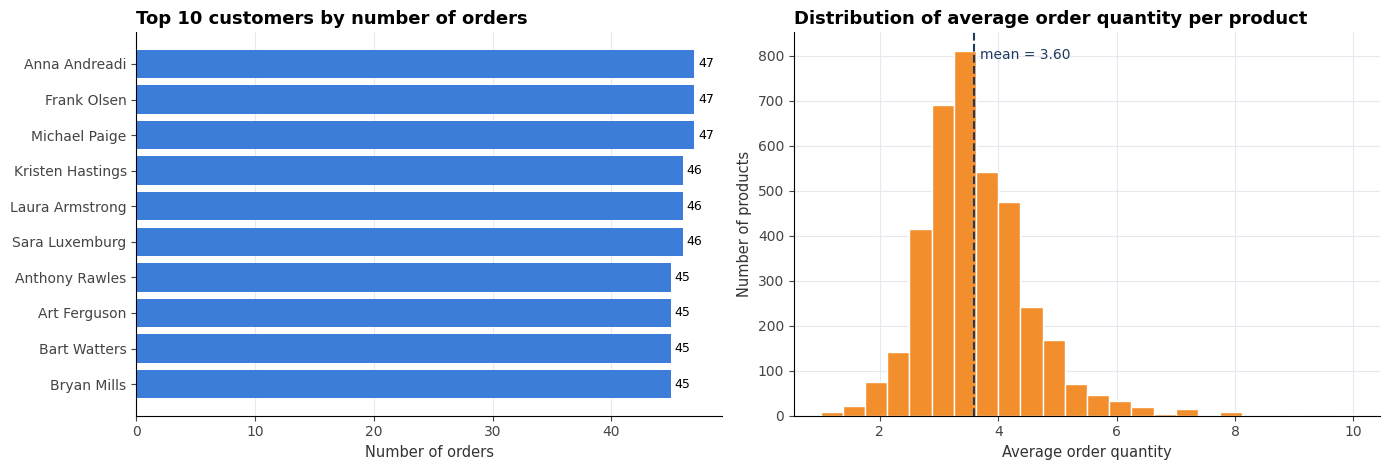

In [6]:
# Visuals for Q7
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

top_c = orders_per_customer.head(TOP_SHOW).iloc[::-1]
bars = axes[0].barh(top_c.index, top_c.values, color=BLUE)
axes[0].bar_label(bars, padding=3, fontsize=9)
axes[0].set_title(f"Top {TOP_SHOW} customers by number of orders")
axes[0].set_xlabel("Number of orders"); axes[0].grid(axis="y", visible=False)

axes[1].hist(avg_qty, bins=24, color=ORANGE, edgecolor="white")
axes[1].axvline(avg_qty.mean(), color=NAVY, ls="--", lw=1.5)
axes[1].text(avg_qty.mean() + 0.1, axes[1].get_ylim()[1] * 0.93, f"mean = {avg_qty.mean():.2f}", color=NAVY)
axes[1].set_title("Distribution of average order quantity per product")
axes[1].set_xlabel("Average order quantity"); axes[1].set_ylabel("Number of products")

plt.tight_layout(); plt.show()

---
## Question 8 – Top 5 products sold the most in the past month  –  `Exp8.csv`

**Approach:** keep only orders from the last 30 days of the dataset → add up `quantity` for every product → sort in descending order → `head(5)`.

> "Past month" is measured back from the **latest order date in the data** (the file ends in April 2014, so *today's* date would give nothing).
> The all-time top 5 is shown next to it for comparison. Ties are broken alphabetically.

In [7]:
# ⚙️ CONFIG ---------------------------------------------------------------
DATA_FILE   = "/content/Exp8.csv"
PRODUCT_COL = "product_name"
QTY_COL     = "quantity"          # set to None if there is no quantity column (rows are counted instead)
DATE_COL    = "order_date"
PAST_DAYS   = 30                  # "past month"
TOP_N       = 5
# --------------------------------------------------------------------------

sales = load_data(DATA_FILE)
check_cols(sales, [PRODUCT_COL, DATE_COL] + ([QTY_COL] if QTY_COL else []))
sales[DATE_COL] = parse_dates(sales[DATE_COL])

latest = sales[DATE_COL].max()
cutoff = latest - pd.Timedelta(days=PAST_DAYS)
past_month = sales[sales[DATE_COL] > cutoff]
print(f"Data runs until {latest:%d %b %Y}  ->  'past month' = {cutoff + pd.Timedelta(days=1):%d %b %Y} to {latest:%d %b %Y}")
print(f"Orders in past month: {len(past_month):,} of {len(sales):,}\n")

def top_products(df, n=TOP_N):
    """Total units sold per product, highest first (ties -> alphabetical)."""
    sold = df.groupby(PRODUCT_COL)[QTY_COL].sum() if QTY_COL else df.groupby(PRODUCT_COL).size()
    sold = sold.sort_index().sort_values(ascending=False, kind="mergesort").head(n)
    sold.index.name, sold.name = "product", "units_sold"
    return sold

top_month, top_all = top_products(past_month), top_products(sales)

print(f"Top {TOP_N} products sold the most in the PAST MONTH:")
display(top_month.to_frame().reset_index().assign(rank=range(1, TOP_N + 1)).set_index("rank"))
print(f"Top {TOP_N} products of ALL TIME (for comparison):")
display(top_all.to_frame().reset_index().assign(rank=range(1, TOP_N + 1)).set_index("rank"))

Data runs until 29 Apr 2014  ->  'past month' = 31 Mar 2014 to 29 Apr 2014
Orders in past month: 1,065 of 37,509

Top 5 products sold the most in the PAST MONTH:


,product,units_sold
rank,,
1,"Ames Interoffice Envelope, Set of 50",22
2,"Ibico Binding Machine, Durable",22
3,"Ibico Index Tab, Clear",20
4,"BIC Highlighters, Fluorescent",18
5,"Smead Lockers, Wire Frame",18


Top 5 products of ALL TIME (for comparison):


,product,units_sold
rank,,
1,Staples,664
2,"Cardinal Index Tab, Clear",245
3,"Eldon File Cart, Single Width",244
4,"Sanford Pencil Sharpener, Water Color",216
5,"Smead File Cart, Single Width",204


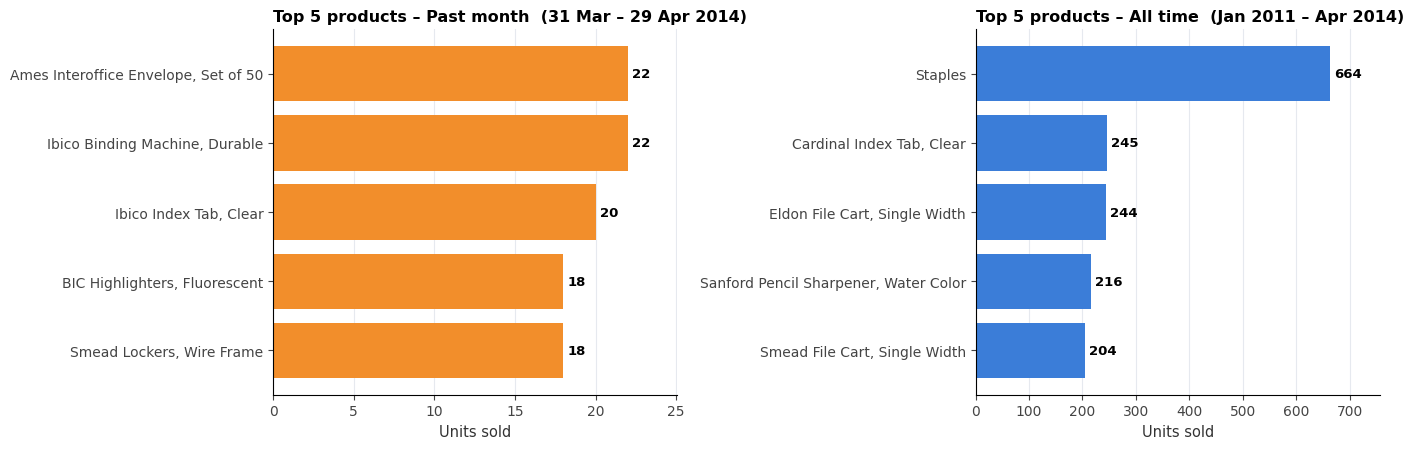

In [8]:
# Visual for Q8
def short(text, n=44):
    return text if len(text) <= n else text[: n - 1] + "…"

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
panels = [(top_month, f"Past month  ({cutoff + pd.Timedelta(days=1):%d %b} – {latest:%d %b %Y})", ORANGE),
          (top_all,   f"All time  ({sales[DATE_COL].min():%b %Y} – {latest:%b %Y})", BLUE)]
for ax, (ser, title, color) in zip(axes, panels):
    s = ser.iloc[::-1]
    bars = ax.barh([short(x) for x in s.index], s.values, color=color)
    ax.bar_label(bars, padding=3, fontsize=9.5, fontweight="bold")
    ax.set_title(f"Top {TOP_N} products – {title}", fontsize=11.5)
    ax.set_xlabel("Units sold"); ax.grid(axis="y", visible=False)
    ax.set_xlim(0, s.max() * 1.14)
plt.tight_layout(); plt.show()

---
## Question 9 – Property analysis (Pandas)  –  `Exp9.csv`

1. Average listing price in each location → `groupby(location)[price].mean()`
2. Number of properties with more than 4 bedrooms → boolean filter `bedrooms > 4`
3. Property with the largest area → `idxmax()` on the area column

> **Note:** this housing dataset has **no property-ID and no location column**.
> * A property ID is created automatically from the row number (`ID_COL = None`).
> * `prefarea` (is the house in a *preferred area*: yes / no) is used as the "location". You can switch `LOCATION_COL` to `"furnishingstatus"`, `"mainroad"`, `"airconditioning"` … and the whole notebook updates.

In [9]:
# ⚙️ CONFIG ---------------------------------------------------------------
DATA_FILE     = "/content/Exp9.csv"
ID_COL        = None             # None -> property IDs are generated (1, 2, 3 ...)
LOCATION_COL  = "prefarea"       # group-by column acting as "location"
BEDROOMS_COL  = "bedrooms"
AREA_COL      = "area"
PRICE_COL     = "price"
BEDROOM_LIMIT = 4                # "more than four bedrooms"
# --------------------------------------------------------------------------

property_data = load_data(DATA_FILE)
check_cols(property_data, [LOCATION_COL, BEDROOMS_COL, AREA_COL, PRICE_COL] + ([ID_COL] if ID_COL else []))
if ID_COL is None:
    ID_COL = "property_id"
    property_data.insert(0, ID_COL, range(1, len(property_data) + 1))

print(f"{len(property_data):,} properties, {property_data.shape[1]} columns")
show(property_data[[ID_COL, LOCATION_COL, BEDROOMS_COL, AREA_COL, PRICE_COL]], n=5, **{PRICE_COL: "{:,.0f}"})

# 1) Average listing price of properties in each location
avg_price = (property_data.groupby(LOCATION_COL)[PRICE_COL].agg(["count", "mean"])
             .rename(columns={"count": "properties", "mean": "avg_listing_price"})
             .sort_values("avg_listing_price", ascending=False))
print(f"\n1) Average listing price by '{LOCATION_COL}'")
show(avg_price, avg_listing_price="{:,.0f}")

# 2) Number of properties with more than four bedrooms
many_bedrooms = property_data[property_data[BEDROOMS_COL] > BEDROOM_LIMIT]
print(f"2) Properties with more than {BEDROOM_LIMIT} bedrooms: {len(many_bedrooms)}  "
      f"({len(many_bedrooms) / len(property_data):.1%} of all properties)")
print("   Their bedroom counts:", many_bedrooms[BEDROOMS_COL].value_counts().sort_index().to_dict())

# 3) Property with the largest area
largest = property_data[property_data[AREA_COL] == property_data[AREA_COL].max()]
print(f"\n3) Property with the largest area ({property_data[AREA_COL].max():,} sq ft):")
show(largest, **{PRICE_COL: "{:,.0f}"})

545 properties, 14 columns


,property_id,prefarea,bedrooms,area,price
0,1,yes,4,7420,"13,300,000"
1,2,no,4,8960,"12,250,000"
2,3,yes,3,9960,"12,250,000"
3,4,yes,4,7500,"12,215,000"
4,5,no,4,7420,"11,410,000"



1) Average listing price by 'prefarea'


,properties,avg_listing_price
prefarea,,
yes,128,"5,879,046"
no,417,"4,425,299"


2) Properties with more than 4 bedrooms: 12  (2.2% of all properties)
   Their bedroom counts: {5: 10, 6: 2}

3) Property with the largest area (16,200 sq ft):


,property_id,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
7,8,"10,150,000",16200,5,3,2,yes,no,no,no,no,0,no,unfurnished


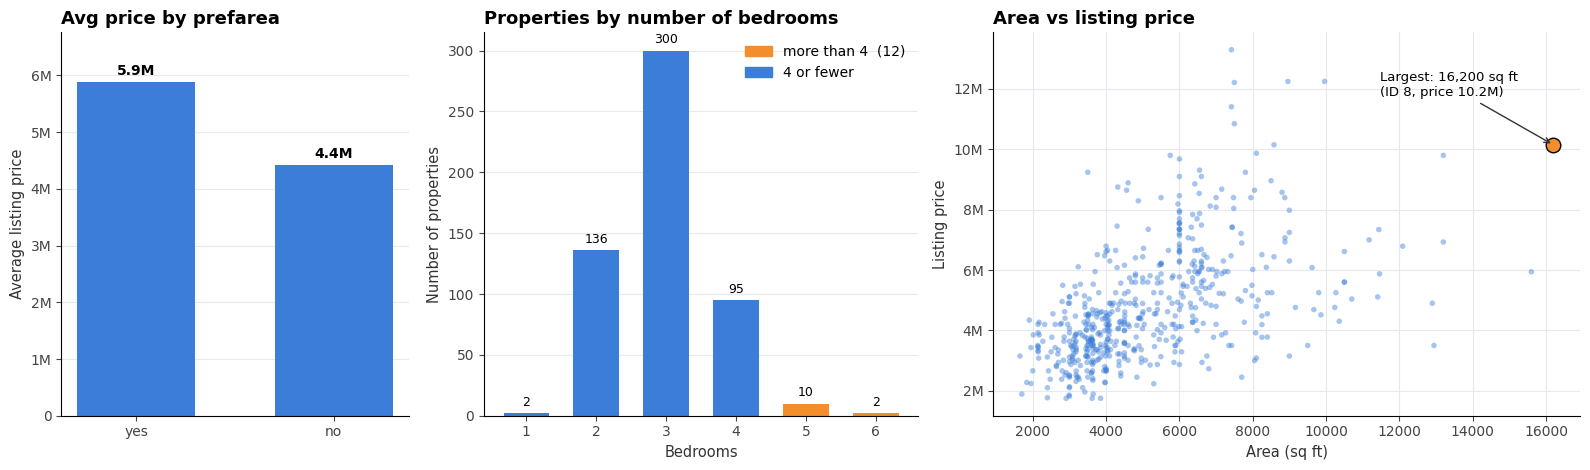

In [10]:
# Visuals for Q9
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), gridspec_kw={"width_ratios": [0.8, 1, 1.35]})

# (a) average price by location
ax = axes[0]
bars = ax.bar(avg_price.index.astype(str), avg_price["avg_listing_price"], color=BLUE, width=0.6)
ax.bar_label(bars, labels=[human(v) for v in avg_price["avg_listing_price"]], padding=3, fontweight="bold")
ax.set_title(f"Avg price by {LOCATION_COL}"); ax.set_ylabel("Average listing price")
ax.yaxis.set_major_formatter(FuncFormatter(human)); ax.grid(axis="x", visible=False)
ax.set_ylim(0, avg_price["avg_listing_price"].max() * 1.15)

# (b) properties per bedroom count  (bars above the limit highlighted)
ax = axes[1]
bc = property_data[BEDROOMS_COL].value_counts().sort_index()
bars = ax.bar(bc.index.astype(str), bc.values, color=[ORANGE if b > BEDROOM_LIMIT else BLUE for b in bc.index], width=0.65)
ax.bar_label(bars, padding=3, fontsize=9)
ax.set_title("Properties by number of bedrooms"); ax.set_xlabel("Bedrooms"); ax.set_ylabel("Number of properties")
ax.grid(axis="x", visible=False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=ORANGE), plt.Rectangle((0, 0), 1, 1, color=BLUE)],
          labels=[f"more than {BEDROOM_LIMIT}  ({len(many_bedrooms)})", f"{BEDROOM_LIMIT} or fewer"])

# (c) area vs price, largest property highlighted
ax = axes[2]
ax.scatter(property_data[AREA_COL], property_data[PRICE_COL], s=16, alpha=0.45, color=BLUE, edgecolor="none")
row = largest.iloc[0]
ax.scatter(row[AREA_COL], row[PRICE_COL], s=110, color=ORANGE, edgecolor="black", zorder=3)
ax.annotate(f"Largest: {row[AREA_COL]:,.0f} sq ft\n(ID {row[ID_COL]}, price {human(row[PRICE_COL])})",
            xy=(row[AREA_COL], row[PRICE_COL]), xytext=(-125, 35), textcoords="offset points",
            arrowprops=dict(arrowstyle="->", color="#333"), fontsize=9.5)
ax.set_title("Area vs listing price"); ax.set_xlabel("Area (sq ft)"); ax.set_ylabel("Listing price")
ax.yaxis.set_major_formatter(FuncFormatter(human))
plt.tight_layout(); plt.show()

---
## Question 10 – Line plot and bar plot of monthly sales (Matplotlib)  –  `Exp10.csv`

`Exp10.csv` holds individual orders, so the **monthly sales** are first calculated by adding up `sales` for every month (`resample("MS").sum()`).

1. **Line plot** → `plt.plot()` – the trend over all months
2. **Bar plot** → `plt.bar()` – comparing the 12 months of one chosen year

> **Data cleaning:** the `sales` column contains numbers written with thousands separators (`"1,648"`), which Pandas reads as text – they are converted with `clean_numeric()`.

In [11]:
# ⚙️ CONFIG ---------------------------------------------------------------
DATA_FILE  = "/content/Exp10.csv"
DATE_COL   = "order_date"
SALES_COL  = "sales"
BAR_YEAR   = 2014                # year shown in the bar plot (None -> latest year in the data)
# --------------------------------------------------------------------------

def to_monthly(df, date_col, sales_col):
    """Transaction rows -> total sales per month (index = first day of each month)."""
    check_cols(df, [date_col, sales_col])
    tmp = pd.DataFrame({"date": parse_dates(df[date_col]), "sales": clean_numeric(df[sales_col])}).dropna()
    return tmp.set_index("date")["sales"].resample("MS").sum().rename("monthly_sales")

def line_plot(monthly, title="Monthly Sales – Line Plot"):
    fig, ax = plt.subplots(figsize=(11.5, 5))
    ax.plot(monthly.index, monthly.values, marker="o", ms=4.5, lw=2.2, color=BLUE, label="Monthly sales")
    ax.fill_between(monthly.index, monthly.values, alpha=0.10, color=BLUE)
    peak, low = monthly.idxmax(), monthly.idxmin()
    ax.scatter([peak], [monthly[peak]], s=90, color=ORANGE, zorder=3, edgecolor="black")
    ax.annotate(f"Peak: {human(monthly[peak])}\n{peak:%b %Y}", xy=(peak, monthly[peak]), xytext=(0, 16),
                textcoords="offset points", ha="center", fontsize=9.5, fontweight="bold")
    ax.scatter([low], [monthly[low]], s=70, color=GREY, zorder=3, edgecolor="black")
    ax.annotate(f"Low: {human(monthly[low])}\n{low:%b %Y}", xy=(low, monthly[low]), xytext=(0, -34),
                textcoords="offset points", ha="center", fontsize=9)
    if len(monthly) > 24:
        ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
        ax.xaxis.set_minor_locator(mdates.MonthLocator(bymonth=[4, 7, 10]))
    else:
        ax.xaxis.set_major_locator(mdates.MonthLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
        fig.autofmt_xdate()
    ax.yaxis.set_major_formatter(FuncFormatter(human))
    ax.set_ylim(0, monthly.max() * 1.22)
    ax.set_title(title); ax.set_xlabel("Month"); ax.set_ylabel("Total sales")
    ax.legend(loc="upper left"); plt.tight_layout(); plt.show()

def bar_plot(monthly, year=None, title=None):
    year = year or monthly.index.year.max()
    m = monthly[monthly.index.year == year]
    best = m.idxmax()
    fig, ax = plt.subplots(figsize=(11.5, 5))
    bars = ax.bar(m.index.strftime("%b"), m.values, color=[ORANGE if d == best else BLUE for d in m.index],
                  width=0.68, edgecolor="white")
    ax.bar_label(bars, labels=[human(v) for v in m.values], padding=3, fontsize=9.5)
    ax.axhline(m.mean(), color=NAVY, ls="--", lw=1.3)
    ax.yaxis.set_major_formatter(FuncFormatter(human)); ax.set_ylim(0, m.max() * 1.15)
    ax.set_title(title or f"Monthly Sales {year} – Bar Plot"); ax.set_xlabel("Month"); ax.set_ylabel("Total sales")
    ax.grid(axis="x", visible=False)
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=ORANGE), plt.Rectangle((0, 0), 1, 1, color=BLUE),
                       plt.Line2D([0], [0], color=NAVY, ls="--", lw=1.3)],
              labels=[f"Best month ({best:%b})", "Other months", f"Monthly average ({human(m.mean())})"],
              loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=3)
    plt.tight_layout(); plt.show()

raw = load_data(DATA_FILE)
monthly_sales = to_monthly(raw, DATE_COL, SALES_COL)
print(f"{len(raw):,} order rows  ->  {len(monthly_sales)} months  ({monthly_sales.index.min():%b %Y} to {monthly_sales.index.max():%b %Y})")
display(monthly_sales.head(6).to_frame().assign(monthly_sales=lambda x: x.monthly_sales.map("{:,.0f}".format)))
print(f"Total sales: {monthly_sales.sum():,.0f}   |   Best month: {monthly_sales.idxmax():%b %Y} ({monthly_sales.max():,.0f})")

51,290 order rows  ->  48 months  (Jan 2011 to Dec 2014)


,monthly_sales
date,
2011-01-01,"98,902"
2011-02-01,"91,152"
2011-03-01,"145,726"
2011-04-01,"116,927"
2011-05-01,"146,762"
2011-06-01,"215,214"


Total sales: 12,642,905   |   Best month: Nov 2014 (555,312)


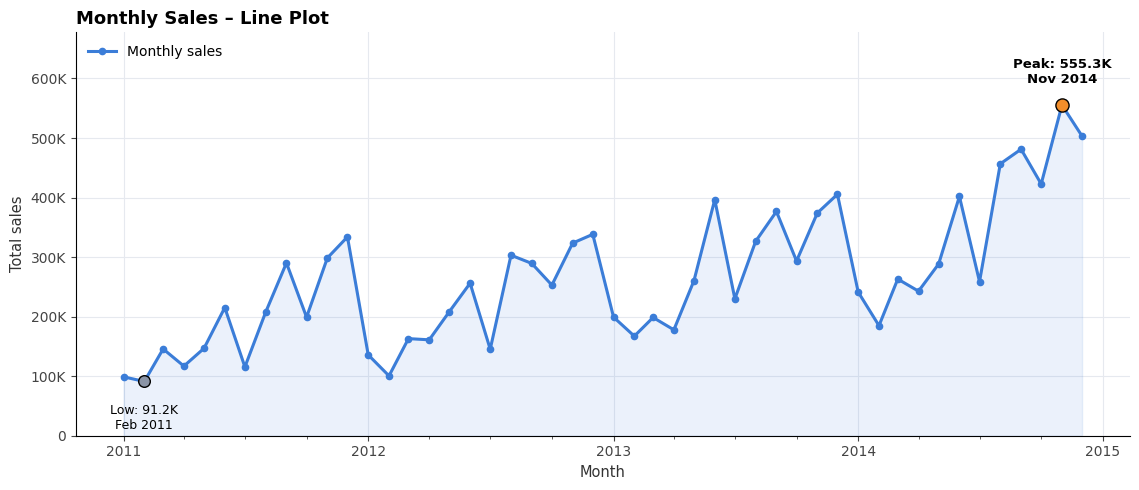

In [12]:
# 1) LINE PLOT of monthly sales (all months)
line_plot(monthly_sales)

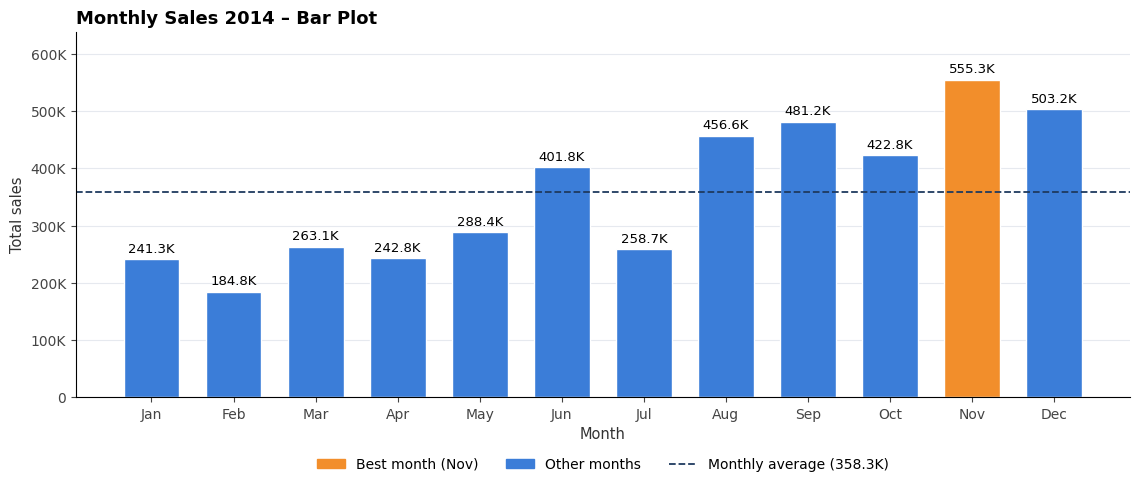

In [14]:
# 2) BAR PLOT of monthly sales (one year)
bar_plot(monthly_sales, BAR_YEAR)

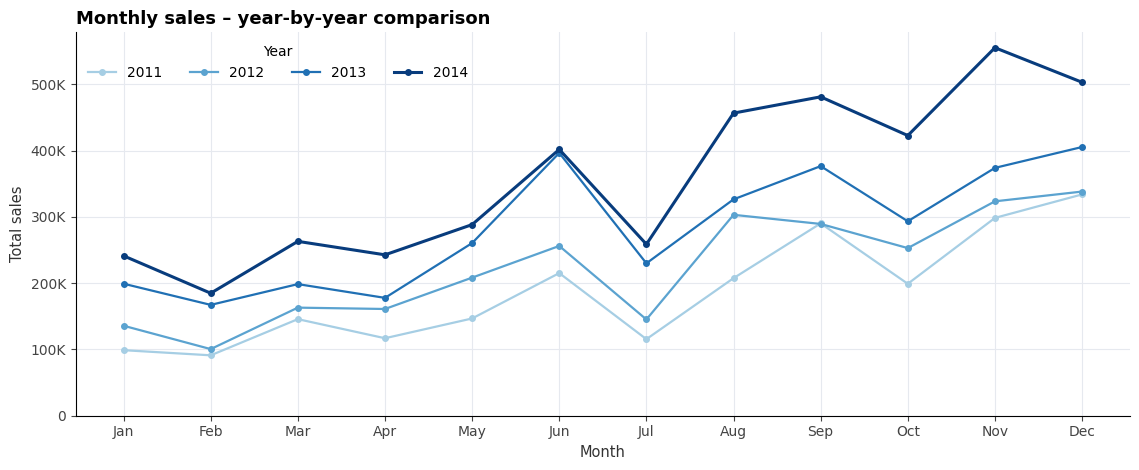

In [15]:
# Extra: one line per year makes the seasonal pattern easy to compare
pivot = monthly_sales.to_frame().assign(year=lambda d: d.index.year, month=lambda d: d.index.month) \
                     .pivot(index="month", columns="year", values="monthly_sales")
cmap = plt.cm.Blues(np.linspace(0.35, 0.95, pivot.shape[1]))
fig, ax = plt.subplots(figsize=(11.5, 4.8))
for color, yr in zip(cmap, pivot.columns):
    ax.plot(pivot.index, pivot[yr], marker="o", ms=4, lw=2.2 if yr == pivot.columns[-1] else 1.6, color=color, label=str(yr))
ax.set_xticks(range(1, 13)); ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.yaxis.set_major_formatter(FuncFormatter(human)); ax.set_ylim(bottom=0)
ax.set_title("Monthly sales – year-by-year comparison"); ax.set_xlabel("Month"); ax.set_ylabel("Total sales")
ax.legend(title="Year", ncol=len(pivot.columns), loc="upper left")
plt.tight_layout(); plt.show()

#### Bonus – the same plots on `Sales_1.xlsx`
`Sales_1.xlsx` already has a month column (`Month_sales`) and an amount column (`Total`), so the exact same functions work on it – only the file and column names change.

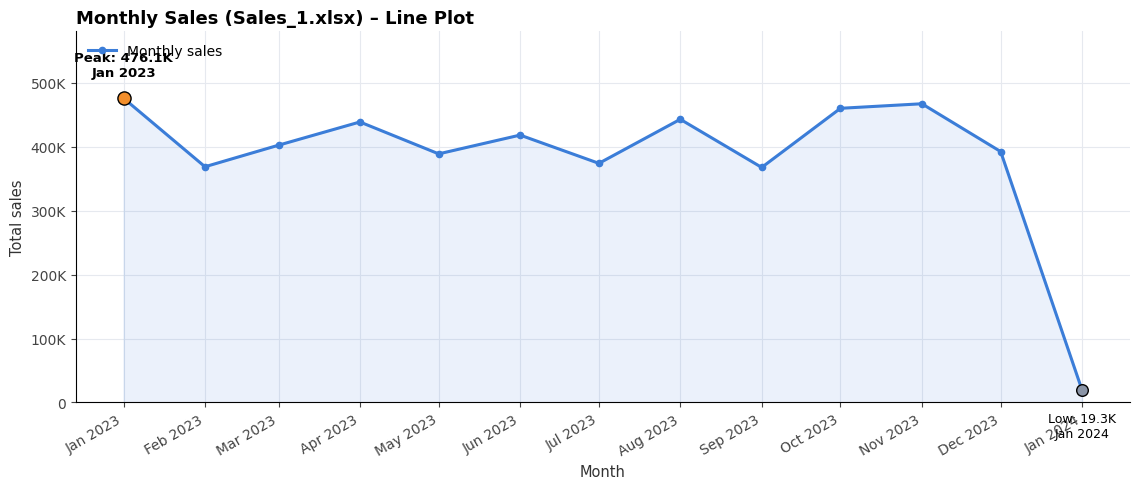

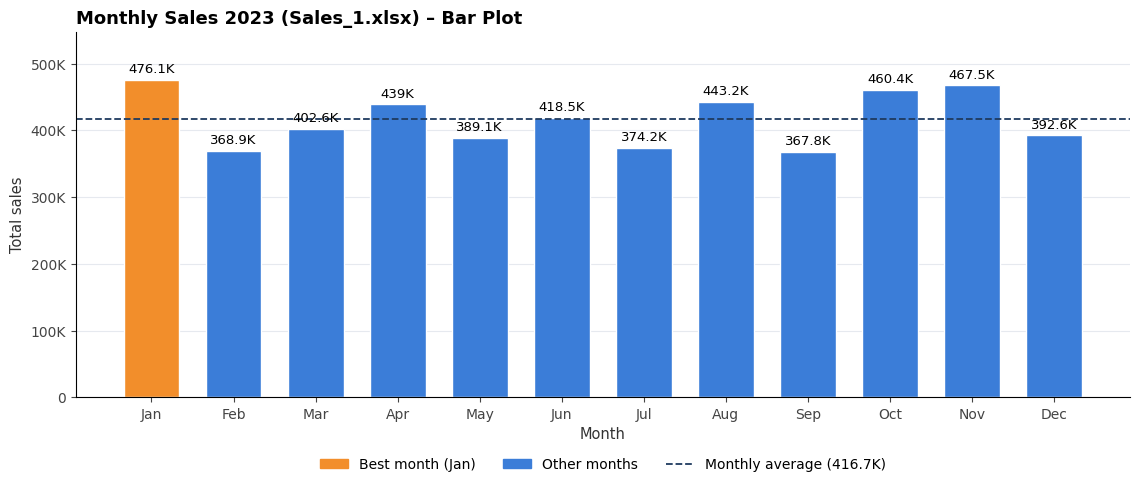

In [17]:
XLSX_FILE, XLSX_DATE_COL, XLSX_SALES_COL = "/content/Sales (1).xlsx", "Month_sales", "Total"

monthly_xlsx = to_monthly(load_data(XLSX_FILE), XLSX_DATE_COL, XLSX_SALES_COL)
line_plot(monthly_xlsx, "Monthly Sales (Sales_1.xlsx) – Line Plot")
bar_plot(monthly_xlsx, 2023, "Monthly Sales 2023 (Sales_1.xlsx) – Bar Plot")